In [1]:
import ast, json, math, re, sys, time
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"figure.figsize": (9, 4), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

# unzipped copies of the .json.gz downloads (gunzip -k data/*.json.gz)
DATA_DIR = Path("data")
REVIEWS_PATH = DATA_DIR / "steam_reviews.json"
ITEMS_PATH   = DATA_DIR / "steam_games.json"
USERS_PATH   = DATA_DIR / "australian_users_items.json"

CACHE = DATA_DIR / "cache"; CACHE.mkdir(exist_ok=True)   # under data/ so git ignores it
REVIEWS_PARQUET = CACHE / "reviews.parquet"

MAX_REVIEW_LINES = None     # None = all ~7.8M rows; change for a faster runthrough!
CHUNK_SIZE       = 250_000  # rows per row-group
FORCE_RECONVERT  = False

HAVE_PARQUET = False

for p in (REVIEWS_PATH, ITEMS_PATH, USERS_PATH):
    if p.exists():
        print(f"{p.name:28s} OK       {p.stat().st_size / 1e6:>9.1f} MB")
    else:
        print(f"{p.name:28s} MISSING")

steam_reviews.json           OK          4273.2 MB
steam_games.json             OK            21.2 MB
australian_users_items.json  OK           553.1 MB


## Parsing

V2 files are not valid JSON. they are the Python `repr` output: single quotes, `u''` prefixes, and `True`/`False`/`None` rather than `true`/`false`/`null`. 

`json.loads` fails on basically every line, so we use `ast.literal_eval` as the primary parser with `json.loads` as a fast path for any line that happens to be good, valid JSON

In [2]:
def parse_line(line):
    """parses one line of a V2 file; returns a dict, or None if unparseable"""

    line = line.strip()
    if not line:
        return None
    try:
        obj = ast.literal_eval(line)
    except (ValueError, SyntaxError, MemoryError, RecursionError):
        try:
            obj = json.loads(line)
        except Exception:
            return None
    return obj if isinstance(obj, dict) else None


def peek(path, n=2):
    """show first n parsed records and the raw first line"""
    with open(path, "r", encoding="utf-8", errors="replace") as fh:
        raw = fh.readline()
        print("RAW:", raw[:300], "\n")
        fh.seek(0)
        out = []
        for i, line in enumerate(fh):
            if i >= n: break
            out.append(parse_line(line))
    return out

peek(ITEMS_PATH, 1)

RAW: {u'publisher': u'Kotoshiro', u'genres': [u'Action', u'Casual', u'Indie', u'Simulation', u'Strategy'], u'app_name': u'Lost Summoner Kitty', u'title': u'Lost Summoner Kitty', u'url': u'http://store.steampowered.com/app/761140/Lost_Summoner_Kitty/', u'release_date': u'2018-01-04', u'tags': [u'Strategy' 



[{'publisher': 'Kotoshiro',
  'genres': ['Action', 'Casual', 'Indie', 'Simulation', 'Strategy'],
  'app_name': 'Lost Summoner Kitty',
  'title': 'Lost Summoner Kitty',
  'url': 'http://store.steampowered.com/app/761140/Lost_Summoner_Kitty/',
  'release_date': '2018-01-04',
  'tags': ['Strategy', 'Action', 'Indie', 'Casual', 'Simulation'],
  'discount_price': 4.49,
  'reviews_url': 'http://steamcommunity.com/app/761140/reviews/?browsefilter=mostrecent&p=1',
  'specs': ['Single-player'],
  'price': 4.99,
  'early_access': False,
  'id': '761140',
  'developer': 'Kotoshiro'}]

## item metadata and cleaning

In [3]:
t0 = time.time()
items_raw, bad_items = [], 0
with open(ITEMS_PATH, "r", encoding="utf-8", errors="replace") as fh:
    for line in fh:
        rec = parse_line(line)
        if rec is None:
            bad_items += 1
        else:
            items_raw.append(rec)

items = pd.DataFrame(items_raw)
print(f"parsed {len(items):,} items, {bad_items:,} unparseable lines, {time.time()-t0:.1f}s")
print("\ncolumns:", list(items.columns))
print(f"\nmissingness (fraction of rows):")
print((items.isna().mean().sort_values(ascending=False) * 100).round(1).to_string())

parsed 32,135 items, 0 unparseable lines, 1.8s

columns: ['publisher', 'genres', 'app_name', 'title', 'url', 'release_date', 'tags', 'discount_price', 'reviews_url', 'specs', 'price', 'early_access', 'id', 'developer', 'sentiment', 'metascore']

missingness (fraction of rows):
discount_price    99.3
metascore         91.7
publisher         25.1
sentiment         22.3
developer         10.3
genres            10.2
release_date       6.4
title              6.4
price              4.3
specs              2.1
tags               0.5
app_name           0.0
reviews_url        0.0
id                 0.0
url                0.0
early_access       0.0


In [4]:
# looking at price : what types and what literal values?
print("dtype census of raw `price`:")
print(items["price"].map(lambda v: type(v).__name__).value_counts().to_string())

str_prices = items.loc[items["price"].map(lambda v: isinstance(v, str)), "price"]
print(f"\n{len(str_prices):,} string-valued prices; most common literals:")
print(str_prices.value_counts().head(25).to_string())

dtype census of raw `price`:
price
float    30225
str       1910

1,910 string-valued prices; most common literals:
price
Free                             905
Free to Play                     520
Free To Play                     462
Free Mod                           4
Free Demo                          3
Play Now                           2
Third-party                        2
Play for Free!                     2
Play WARMACHINE: Tactics Demo      1
Install Theme                      1
Install Now                        1
Free HITMAN™ Holiday Pack          1
Play the Demo                      1
Starting at $499.00                1
Starting at $449.00                1
Free to Try                        1
Free Movie                         1
Free to Use                        1


In [5]:
FREE_TOKENS = ("free", "no cost", "play for free")

def clean_price(v):
    """Return (price_in_dollars, reason). NaN price means unusable as a label."""
    if v is None or (isinstance(v, float) and math.isnan(v)):
        return np.nan, "missing"
    if isinstance(v, bool):
        return np.nan, "unparseable"
    if isinstance(v, (int, float)):
        f = float(v)
        return (f, "numeric") if np.isfinite(f) and f >= 0 else (np.nan, "unparseable")
    s = str(v).strip()
    if not s:
        return np.nan, "empty"
    low = s.lower()
    if any(tok in low for tok in FREE_TOKENS):
        return 0.0, "free_string"
    m = re.search(r"\$?\s*([\d,]+\.?\d*)", s)
    if m:
        try:
            return float(m.group(1).replace(",", "")), "parsed_string"
        except ValueError:
            pass
    return np.nan, "unparseable"


cleaned = items["price"].map(clean_price)
items["price_clean"]  = [c[0] for c in cleaned]
items["price_reason"] = [c[1] for c in cleaned]

print("cleaning outcome by reason:")
summary = (items.groupby("price_reason")
                .agg(n=("price_reason", "size"), median_price=("price_clean", "median"))
                .sort_values("n", ascending=False))
print(summary.to_string())

usable = items["price_clean"].notna()
print(f"\nitems with a usable price: {usable.sum():,} / {len(items):,} ({usable.mean()*100:.1f}%)")
print(f"of those, free (price == 0): {(items.loc[usable, 'price_clean'] == 0).mean()*100:.1f}%")
print("\nunparseable examples:")
print(items.loc[items["price_reason"] == "unparseable", "price"].drop_duplicates().head(15).to_string())

cleaning outcome by reason:
                   n  median_price
price_reason                      
numeric        28848          4.99
free_string     1900          0.00
missing         1377           NaN
unparseable        8           NaN
parsed_string      2        474.00

items with a usable price: 30,750 / 32,135 (95.7%)
of those, free (price == 0): 6.2%

unparseable examples:
2405                       Install Now
2871     Play WARMACHINE: Tactics Demo
3832                     Install Theme
3918                       Third-party
4026                          Play Now
22734                    Play the Demo


count    30750.00
mean         8.90
std         16.34
min          0.00
10%          0.99
25%          2.99
50%          4.99
75%          9.99
90%         19.99
95%         24.99
99%         54.99
max        995.00


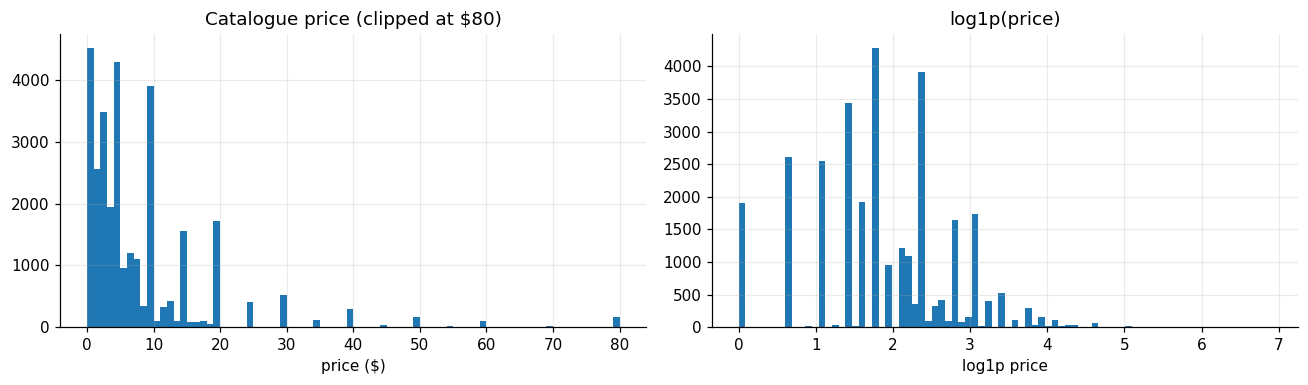


top 15 exact price points in the catalogue:
price_clean
4.99     4278
9.99     3902
2.99     3429
0.99     2607
1.99     2541
3.99     1918
0.00     1900
19.99    1719
14.99    1557
6.99     1199
7.99     1095
5.99      948
29.99     520
12.99     417
24.99     402


In [6]:
# catalogue-level price distribution
# this is NOT the target distribution!!!
# the target is weighted by review events
pc = items.loc[usable, "price_clean"]
print(pc.describe(percentiles=[.1, .25, .5, .75, .9, .95, .99]).round(2).to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(pc.clip(upper=80), bins=80)
ax[0].set_title("Catalogue price (clipped at $80)"); ax[0].set_xlabel("price ($)")
ax[1].hist(np.log1p(pc), bins=80)
ax[1].set_title("log1p(price)"); ax[1].set_xlabel("log1p price")
plt.tight_layout(); plt.show()

print("\ntop 15 exact price points in the catalogue:")
print(pc.value_counts().head(15).to_string())

### item lookup tables

`price_map` and `genre_map` are both are keyed on `id` as a string, since `product_id` in the reviews file is a string.

the metadata file repeats some `id` values; left unhandled, the duplicates give `price_map` a non-unique index

below cell investigates how many ids were affected and if the copies have a difference on price; if they do, then whichever is picked changes the label

In [7]:
items["release_dt"] = pd.to_datetime(items.get("release_date"), errors="coerce")

# check for missing id 
_raw_id = items["id"]
items["id"] = _raw_id.astype(str)
ok_id = _raw_id.notna() & ~items["id"].isin(["nan", "None", "<NA>", ""])
if (~ok_id).any():
    print(f"rows with no usable id: {(~ok_id).sum():,} (excluded from the lookups)")

dups = items.loc[ok_id, "id"].duplicated(keep=False)
n_dup_ids = items.loc[ok_id].loc[dups, "id"].nunique()
print(f"rows carrying a repeated id: {dups.sum():,} across {n_dup_ids:,} distinct ids")

if dups.any():
    conflicting = items.loc[ok_id].loc[dups].groupby("id")["price_clean"].nunique(dropna=True) > 1
    print(f"  ...ids whose copies disagree on price: {int(conflicting.sum()):,}")
    if conflicting.any():
        show = list(conflicting[conflicting].index[:3])
        print("\n  examples of conflicting duplicates:")
        print(items.loc[items["id"].isin(show), ["id", "app_name", "price", "price_clean"]]
                   .sort_values("id").to_string(index=False))

# LABEL POLICY: prefer a row that has a usable price; for equals, keep the last in file order
items_u = (items.loc[ok_id]
                .assign(_has_price=lambda d: d["price_clean"].notna())
                .sort_values("_has_price", kind="mergesort")
                .drop_duplicates(subset="id", keep="last")
                .drop(columns="_has_price")
                .set_index("id"))

def _as_list(v):
    return v if isinstance(v, list) else []

price_map = items_u["price_clean"].dropna()
genre_map = items_u["genres"].map(_as_list)
tag_map   = items_u["tags"].map(_as_list)
assert price_map.index.is_unique, "price_map index must be unique before any .map()"

print(f"\nunique items after dedupe: {len(items_u):,}")
print(f"price_map: {len(price_map):,} items with a usable price")
print(f"release dates span {items_u['release_dt'].min()} .. {items_u['release_dt'].max()}")
print("\nmost common genres:")
print(pd.Series(Counter(g for gs in genre_map for g in gs)).sort_values(ascending=False).head(12).to_string())

rows with no usable id: 2 (excluded from the lookups)
rows carrying a repeated id: 2 across 1 distinct ids
  ...ids whose copies disagree on price: 0



unique items after dedupe: 32,132
price_map: 30,747 items with a usable price
release dates span 1970-07-15 00:00:00 .. 2021-12-31 00:00:00

most common genres:
Indie                    15858
Action                   11319
Casual                    8282
Adventure                 8242
Strategy                  6957
Simulation                6699
RPG                       5479
Free to Play              2031
Early Access              1462
Sports                    1257
Massively Multiplayer     1108
Racing                    1083


## review stream

looking at row counts, date coverage, per-user volume, and the duplicate/tie issues that affect building sequences

In [ ]:
# the reviews file is ~4.3 GB of python-repr lines: parse it once (dropping the review text),
# cache the result as parquet, and read the parquet on every later run
REVIEW_COLS = ["username", "user_id", "product_id", "date", "hours",
               "products", "found_funny", "early_access"]

t0 = time.time()
use_cache = MAX_REVIEW_LINES is None   # a partial read is never cached, so it can't pass for the full file

if use_cache and REVIEWS_PARQUET.exists() and not FORCE_RECONVERT:
    rev = pd.read_parquet(REVIEWS_PARQUET)
else:
    rows = []
    with open(REVIEWS_PATH, "r", encoding="utf-8", errors="replace") as fh:
        for i, line in enumerate(fh):
            if MAX_REVIEW_LINES is not None and i >= MAX_REVIEW_LINES:
                break
            rec = parse_line(line)
            if rec is not None:
                rows.append([rec.get(c) for c in REVIEW_COLS])
    rev = pd.DataFrame(rows, columns=REVIEW_COLS)
    rev["date"] = pd.to_datetime(rev["date"], errors="coerce")
    if use_cache:
        rev.to_parquet(REVIEWS_PARQUET, row_group_size=CHUNK_SIZE)

# the crawl picked up ~831k reviews twice (identical except page position): keep one copy,
# then keep only a user's first review of each game
n_raw = len(rev)
rev = rev.drop_duplicates().sort_values("date", kind="mergesort")
rev = rev[rev["user_id"].isna() | ~rev.duplicated(["user_id", "product_id"])].reset_index(drop=True)

print(f"loaded {n_raw:,} reviews, {len(rev):,} after removing duplicates, in {time.time()-t0:.1f}s")
rev.head(3)

In [9]:
print(f"reviews          {len(rev):,}")
print(f"unique users     {rev['user_id'].nunique():,}")
print(f"unique items     {rev['product_id'].nunique():,}")
print(f"null dates       {rev['date'].isna().sum():,}")
print(f"date range       {rev['date'].min().date()} .. {rev['date'].max().date()}")
print(f"early access     {rev['early_access'].mean()*100:.1f}% of reviews")
print(f"\nhours played:")
print(rev["hours"].describe(percentiles=[.25, .5, .75, .95, .99]).round(1).to_string())

dup = rev.duplicated(subset=["user_id", "product_id"], keep=False)
print(f"\nrows in a duplicated (user, item) pair: {dup.sum():,} ({dup.mean()*100:.2f}%)")

same_day = rev.duplicated(subset=["user_id", "date"], keep=False)
print(f"rows sharing a (user, date) with another review: {same_day.sum():,} ({same_day.mean()*100:.2f}%)"
      "  <- these need a tiebreak when ordering")

reviews          7,793,069


unique users     1,485,611
unique items     15,474
null dates       0


date range       2010-10-15 .. 2018-01-05
early access     13.8% of reviews

hours played:


count    7766532.0
mean         111.8
std          392.9
min            0.0
25%            4.0
50%           15.3
75%           59.7
95%          509.8
99%         1741.0
max        42100.7



rows in a duplicated (user, item) pair: 5,272,770 (67.66%)


rows sharing a (user, date) with another review: 5,579,388 (71.59%)  <- these need a tiebreak when ordering


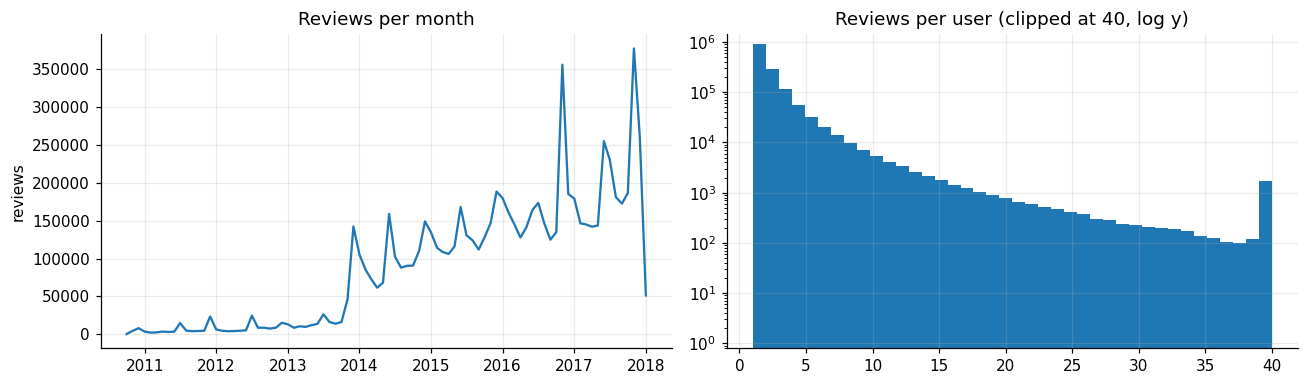

reviews per user:
count    1485611.0
mean           2.1
std            4.0
min            1.0
50%            1.0
75%            2.0
90%            4.0
99%           14.0
max         1254.0
  users with >= 1 reviews: 1,485,611 (100.0%)  covering  3,176,223 reviews
  users with >= 2 reviews:   581,343 ( 39.1%)  covering  2,271,955 reviews
  users with >= 3 reviews:   287,352 ( 19.3%)  covering  1,683,973 reviews
  users with >= 5 reviews:   114,797 (  7.7%)  covering  1,109,777 reviews

most prolific users (check for bots before modelling):


user_id
76561198011965365    1254
76561198094803808     900
76561197969749884     750
76561198094321628     669
76561198073092169     549
76561197967685936     516
76561198030784015     512
76561198046675266     498
76561198069159152     361
76561198318964928     350


In [10]:
vol = rev.set_index("date").resample("MS").size()
per_user = rev.groupby("user_id").size()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(vol.index, vol.values)
ax[0].set_title("Reviews per month"); ax[0].set_ylabel("reviews")
ax[1].hist(per_user.clip(upper=40), bins=40)
ax[1].set_yscale("log"); ax[1].set_ylim(bottom=0.8)
ax[1].set_title("Reviews per user (clipped at 40, log y)")
plt.tight_layout(); plt.show()

print("reviews per user:")
print(per_user.describe(percentiles=[.5, .75, .9, .99]).round(1).to_string())
for k in (1, 2, 3, 5):
    print(f"  users with >= {k} reviews: {(per_user >= k).sum():>9,} "
          f"({(per_user >= k).mean()*100:5.1f}%)  "
          f"covering {per_user[per_user >= k].sum():>10,} reviews")
print("\nmost prolific users (check for bots before modelling):")
print(per_user.sort_values(ascending=False).head(10).to_string())

## how much of the review stream can be labelled

this is important.

In [11]:
rev["price"] = rev["product_id"].astype(str).map(price_map).astype("float64")

item_ids_in_rev = set(rev["product_id"].unique())
matched_items   = item_ids_in_rev & set(price_map.index)

print(f"distinct items in reviews              {len(item_ids_in_rev):,}")
print(f"  ...present in metadata with a price  {len(matched_items):,} "
      f"({len(matched_items)/len(item_ids_in_rev)*100:.1f}%)")
print(f"\nreview events                          {len(rev):,}")
print(f"  ...labellable (review-weighted)      {rev['price'].notna().sum():,} "
      f"({rev['price'].notna().mean()*100:.1f}%)   <-- THE NUMBER")

lost = rev.loc[rev["price"].isna(), "product_id"].value_counts()
print(f"\ntop unlabellable items by review volume (candidates for bundle-based imputation):")
print(lost.head(12).to_string())

distinct items in reviews              15,474
  ...present in metadata with a price  15,295 (98.8%)

review events                          7,793,069
  ...labellable (review-weighted)      7,723,661 (99.1%)   <-- THE NUMBER

top unlabellable items by review volume (candidates for bundle-based imputation):
product_id
261570    11242
51100      6550
203290     4496
349700     4333
272060     3892
270170     3388
340        3063
214190     2782
302380     2469
72200      2131
430440     1588
268850     1231


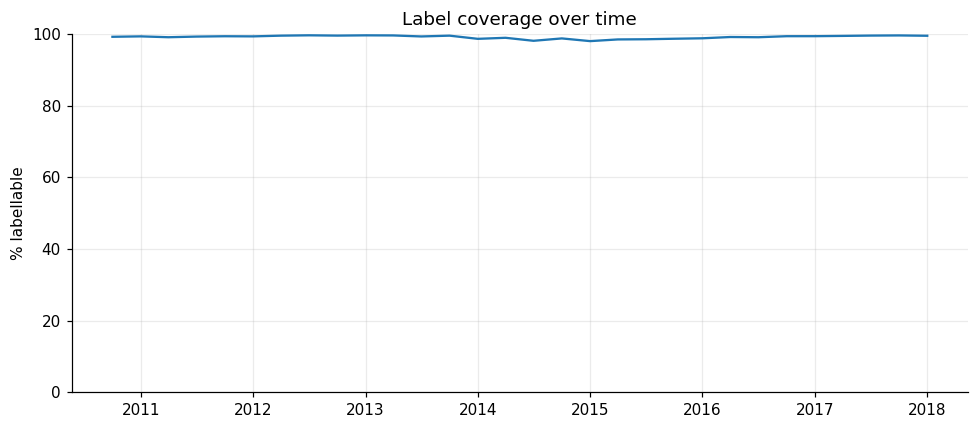

In [12]:
# if label coverage changes over time, this could bias the test set.
cov = (rev.assign(ok=rev["price"].notna())
          .set_index("date").resample("QS")["ok"].mean())
plt.plot(cov.index, cov.values * 100)
plt.ylabel("% labellable"); plt.title("Label coverage over time"); plt.ylim(0, 100)
plt.tight_layout(); plt.show()

## target distribution on review events

count    7723661.00
mean          16.29
std           16.49
min            0.00
10%            0.00
25%            4.99
50%           14.99
75%           19.99
90%           39.99
95%           39.99
99%           59.99
max          771.71

P(free) on review events: 19.1%
P(free) on the catalogue:  6.2%   <- note the gap

mean $16.29 | median $14.99 | mean of paid only $20.14


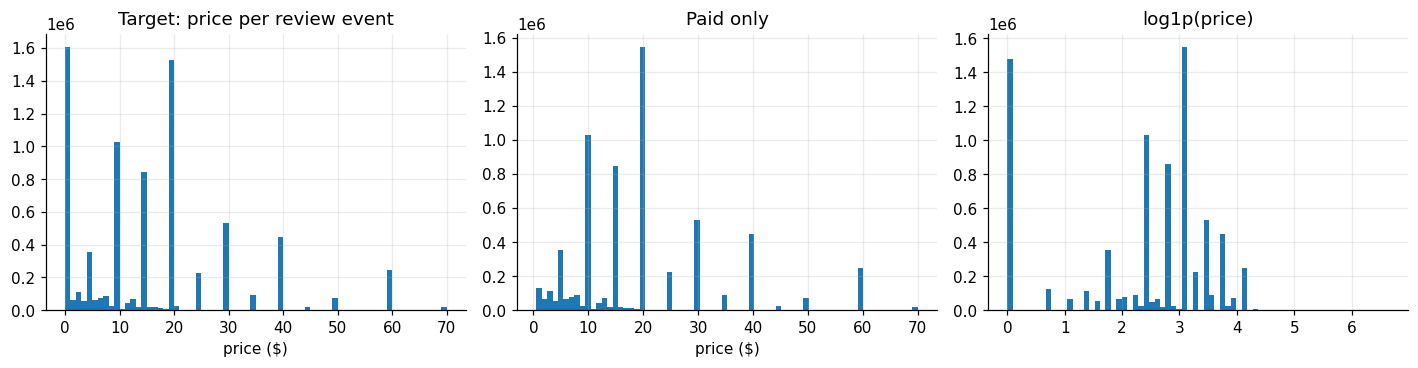


top 15 exact price points by review volume:
price
19.99    1523702
0.00     1476269
9.99     1027772
14.99     841320
29.99     531921
39.99     446226
4.99      351676
59.99     234239
24.99     225970
0.99      126208
2.99      113246
34.99      91414
7.99       87429
6.99       75794
49.99      71512


In [13]:
lab = rev.loc[rev["price"].notna() & rev["date"].notna()].copy()
y = lab["price"]

print(y.describe(percentiles=[.1, .25, .5, .75, .9, .95, .99]).round(2).to_string())
print(f"\nP(free) on review events: {(y == 0).mean()*100:.1f}%")
print(f"P(free) on the catalogue:  {(price_map == 0).mean()*100:.1f}%   <- note the gap")
print(f"\nmean ${y.mean():.2f} | median ${y.median():.2f} | "
      f"mean of paid only ${y[y > 0].mean():.2f}")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].hist(y.clip(upper=70), bins=70)
ax[0].set_title("Target: price per review event"); ax[0].set_xlabel("price ($)")
ax[1].hist(y[y > 0].clip(upper=70), bins=70)
ax[1].set_title("Paid only"); ax[1].set_xlabel("price ($)")
ax[2].hist(np.log1p(y), bins=70)
ax[2].set_title("log1p(price)")
plt.tight_layout(); plt.show()

print("\ntop 15 exact price points by review volume:")
print(y.value_counts().head(15).to_string())

## sequence construction

sort user reviews by time, then for every review after their first, the target is that review's price and the features come from only earlier reviews

same-day ties break on `product_id`

In [14]:
ev = lab.sort_values(["user_id", "date", "product_id"], kind="mergesort").reset_index(drop=True)

g = ev.groupby("user_id", sort=False)["price"]

# Vectorised: cumulative stats over strictly-earlier reviews. Seconds, not minutes.
ev["hist_n"]     = g.cumcount()
ev["hist_mean"]  = (g.cumsum() - ev["price"]) / ev["hist_n"].where(ev["hist_n"] > 0)
ev["last_price"] = g.shift(1)
ev["days_since_last"] = ev.groupby("user_id", sort=False)["date"].diff().dt.days

free_flag = (ev["price"] == 0).astype("float64")
ev["hist_free_share"] = ((free_flag.groupby(ev["user_id"], sort=False).cumsum() - free_flag)
                         / ev["hist_n"].where(ev["hist_n"] > 0))

# Rolling-window and EWM stats need a Python-level pass per group. With ~2.5M users that is
# minutes, not seconds, so they are opt-in. Turn on once the cheap baselines are understood.
COMPUTE_SLOW_HISTORY = False
SLOW_COLS = []
if COMPUTE_SLOW_HISTORY:
    t0 = time.time()
    ev["hist_med5"] = g.transform(lambda s: s.rolling(5, min_periods=1).median().shift(1))
    ev["hist_ewm"]  = g.transform(lambda s: s.ewm(halflife=3).mean().shift(1))
    SLOW_COLS = ["hist_med5", "hist_ewm"]
    print(f"rolling / EWM history stats computed in {time.time()-t0:.0f}s")

usable_rows = ev["hist_n"] >= 1
print(f"labelled review events        {len(ev):,}")
print(f"usable targets (>= 1 history) {usable_rows.sum():,} ({usable_rows.mean()*100:.1f}%)")
print(f"users contributing a target   {ev.loc[usable_rows, 'user_id'].nunique():,}")
print(f"\nhistory length at prediction time:")
print(ev.loc[usable_rows, "hist_n"].describe(percentiles=[.5, .75, .9, .99]).round(1).to_string())

labelled review events        7,723,661
usable targets (>= 1 history) 1,672,919 (21.7%)


users contributing a target   577,230

history length at prediction time:
count    1672919.0
mean           8.0
std           31.4
min            1.0
50%            2.0
75%            6.0
90%           15.0
99%           87.0
max         1233.0


## temporal split?

at training time nothing after *T* is visible, including other users' reviews

In [15]:
T      = ev["date"].quantile(0.80)
T_PRIME = ev["date"].quantile(0.90)
print(f"T  = {T.date()}   T' = {T_PRIME.date()}")

ev["split"] = np.where(ev["date"] < T, "train",
              np.where(ev["date"] < T_PRIME, "val", "test"))

print()
print(ev.loc[usable_rows, "split"].value_counts().reindex(["train", "val", "test"]).to_string())

# a test row whose user has no pre-T history would be a different prediction problem?
users_seen_in_train = set(ev.loc[(ev["split"] == "train"), "user_id"].unique())
test = ev.loc[usable_rows & (ev["split"] == "test")].copy()
test["cold"] = ~test["user_id"].isin(users_seen_in_train)
print(f"\ntest rows {len(test):,} | cold-start {test['cold'].sum():,} ({test['cold'].mean()*100:.1f}%)")
print(f"\nmean target price  train ${ev.loc[ev['split']=='train','price'].mean():.2f} "
      f"| test ${test['price'].mean():.2f}   <- drift check")

T  = 2017-06-24   T' = 2017-10-18



split
train    1277465
val       205787
test      189667



test rows 189,667 | cold-start 51,477 (27.1%)

mean target price  train $15.68 | test $19.87   <- drift check
